In [6]:
import os
import zipfile
from google.colab import files

zip_path = "coco128.zip"
extract_dir = "coco128_data"

if not os.path.exists(zip_path):
    print("Please upload coco128.zip...")
    uploaded = files.upload()
    zip_files = [f for f in uploaded.keys() if f.endswith(".zip")]
    if not zip_files:
        raise FileNotFoundError("No .zip archive was uploaded.")
    zip_path = zip_files[0]

os.makedirs(extract_dir, exist_ok=True)
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print(f"Extracted '{zip_path}' -> '{extract_dir}/'")
for root, dirs, files_list in os.walk(extract_dir):
    level = root.replace(extract_dir, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/ ({len(files_list)} files)")

Please upload coco128.zip...


Saving COCO128.zip to COCO128 (1).zip
Extracted 'COCO128 (1).zip' -> 'coco128_data/'
coco128_data/ (10 files)


In [7]:
from pathlib import Path
import yaml

base_path = Path("coco128_data")
image_files = sorted(
    list(base_path.rglob("*.jpg")) + list(base_path.rglob("*.png"))
)
label_files = sorted(base_path.rglob("*.txt"))

# Exclude non-label text files like README or notes if present
label_files = [p for p in label_files if p.parent.name == "labels"]

# Standard COCO class IDs relevant to traffic scenes
COCO_NAMES = {
    0: "person",
    1: "bicycle",
    2: "car",
    3: "motorcycle",
    5: "bus",
    7: "truck",
    9: "traffic light",
    11: "stop sign",
}

yaml_files = list(base_path.rglob("*.yaml")) + list(base_path.rglob("*.yml"))
if yaml_files:
    with open(yaml_files[0], "r") as f:
        cfg = yaml.safe_load(f)
    if isinstance(cfg, dict) and "names" in cfg:
        if isinstance(cfg["names"], dict):
            COCO_NAMES.update(cfg["names"])
        elif isinstance(cfg["names"], list):
            COCO_NAMES = {i: name for i, name in enumerate(cfg["names"])}

print(f"Images found: {len(image_files)}")
print(f"Label files found: {len(label_files)}")

Images found: 10
Label files found: 0


In [8]:
from collections import Counter

TRAFFIC_IDS = {0, 1, 2, 3, 5, 7, 9, 11}
traffic_counts = Counter()
images_with_traffic = set()

for lbl_path in label_files:
    with open(lbl_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if not parts:
                continue
            cls_id = int(float(parts[0]))
            if cls_id in TRAFFIC_IDS:
                cls_name = COCO_NAMES.get(cls_id, f"class_{cls_id}")
                traffic_counts[cls_name] += 1
                images_with_traffic.add(lbl_path.stem)

print(f"Images containing traffic classes: {len(images_with_traffic)}")
for cls_name, count in traffic_counts.most_common():
    print(f"  {cls_name:15s}: {count}")

Images containing traffic classes: 0


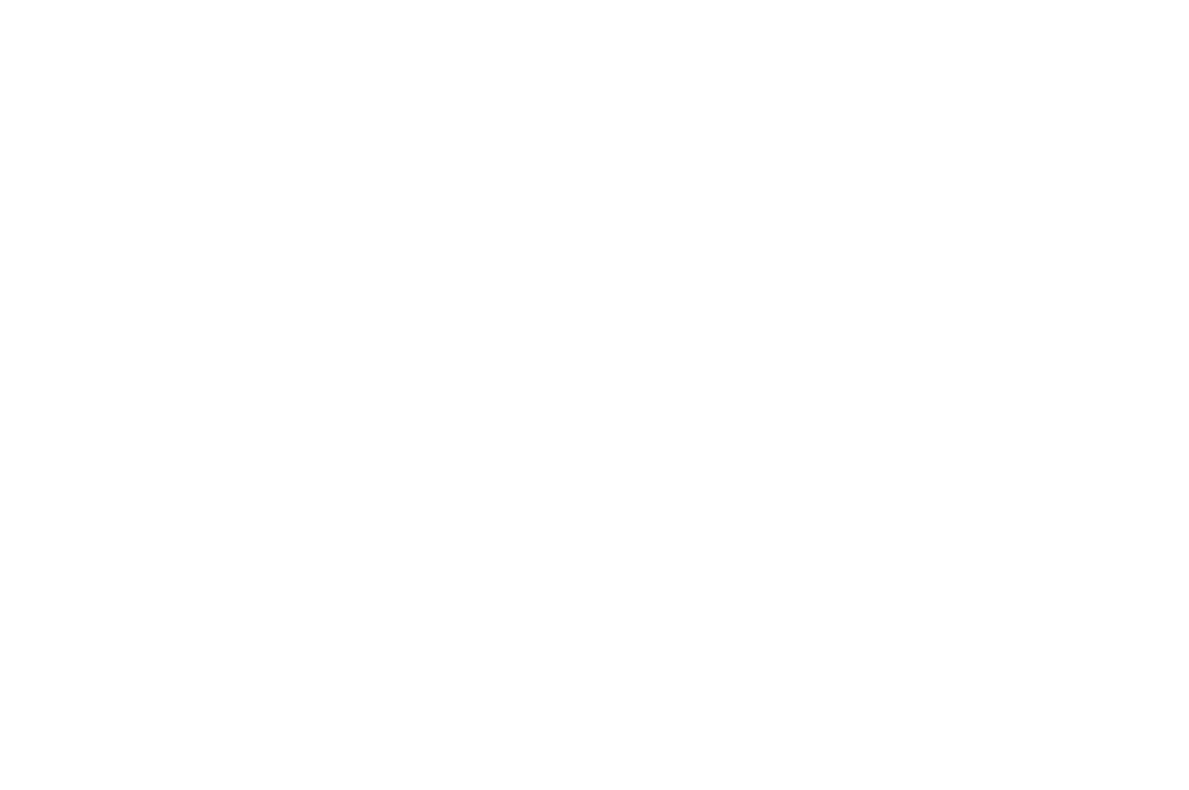

In [9]:
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

label_map = {p.stem: p for p in label_files}
sample_imgs = [p for p in image_files if p.stem in images_with_traffic][:4]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, img_path in zip(axes, sample_imgs):
    img = Image.open(img_path).convert("RGB")
    w, h = img.size
    draw = ImageDraw.Draw(img)

    lbl_path = label_map.get(img_path.stem)
    if lbl_path and lbl_path.exists():
        for line in lbl_path.read_text().splitlines():
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            cls_id = int(float(parts[0]))
            if cls_id not in TRAFFIC_IDS:
                continue
            xc, yc, bw, bh = map(float, parts[1:5])
            x1 = (xc - bw / 2) * w
            y1 = (yc - bh / 2) * h
            x2 = (xc + bw / 2) * w
            y2 = (yc + bh / 2) * h
            name = COCO_NAMES.get(cls_id, str(cls_id))
            draw.rectangle([x1, y1, x2, y2], outline="lime", width=3)
            draw.text((x1 + 2, max(0, y1 - 12)), name, fill="lime")

    ax.imshow(img)
    ax.set_title(img_path.name)
    ax.axis("off")

for ax in axes[len(sample_imgs):]:
    ax.axis("off")

plt.tight_layout()
plt.show()